In [ ]:
from pathlib import Path
import os, sys

# Auto-set repo root (expects Data/ and predictions/ at root)
cwd = Path.cwd()
REPO_ROOT = None
for parent in [cwd, *cwd.parents]:
    if (parent / "Data").exists() and (parent / "predictions").exists():
        REPO_ROOT = parent
        break
if REPO_ROOT is None:
    REPO_ROOT = cwd
os.chdir(REPO_ROOT)

# Add repo-local modules to import path (scripts + notebooks; no src)
src_candidates = [
    REPO_ROOT / "scripts",
    REPO_ROOT / "notebooks",
    REPO_ROOT / "code_repository" / "scripts",
    REPO_ROOT / "code_repository" / "notebooks",
]
for SRC in reversed(src_candidates):
    if SRC.exists() and str(SRC) not in sys.path:
        sys.path.insert(0, str(SRC))

print(f"Working dir: {Path.cwd()}")


Working dir: /mnt/nas/PhD/Code/Ms_paint/code_repository


In [2]:
from analysis.plot_style import apply_style, save_figure, set_save_dir
FIGURE_ID = "figure6"
FIG_DIR = set_save_dir(REPO_ROOT, FIGURE_ID)
apply_style()


In [3]:
from pathlib import Path
import os, glob, json, math
import numpy as np
import pandas as pd
from typing import Dict, Tuple, List, Optional
from joblib import load
from uncertainty.uncertainty_estimator import UncertaintyEstimator


# Non-significant

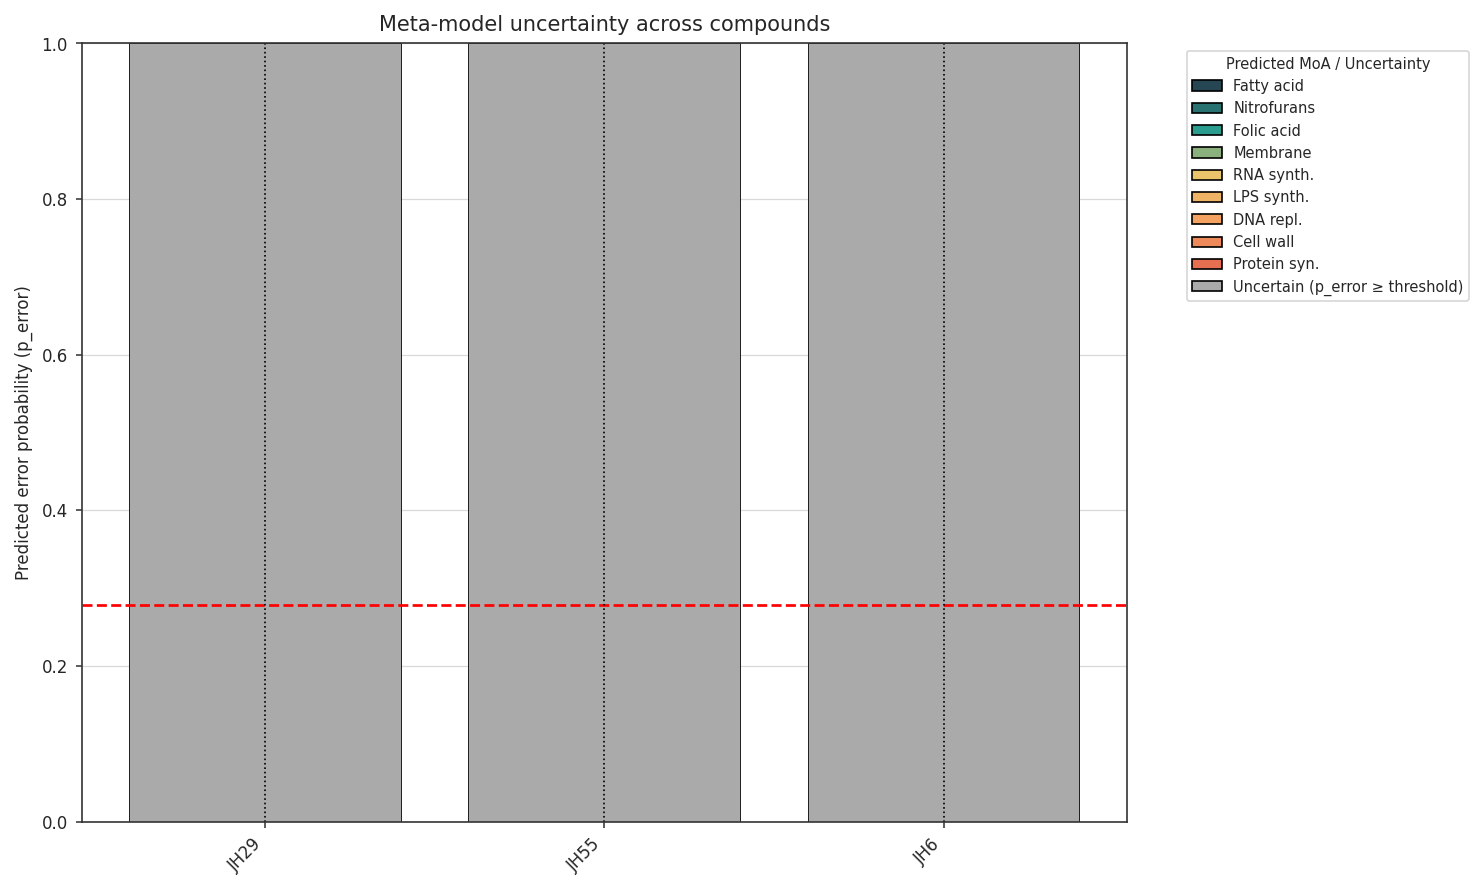

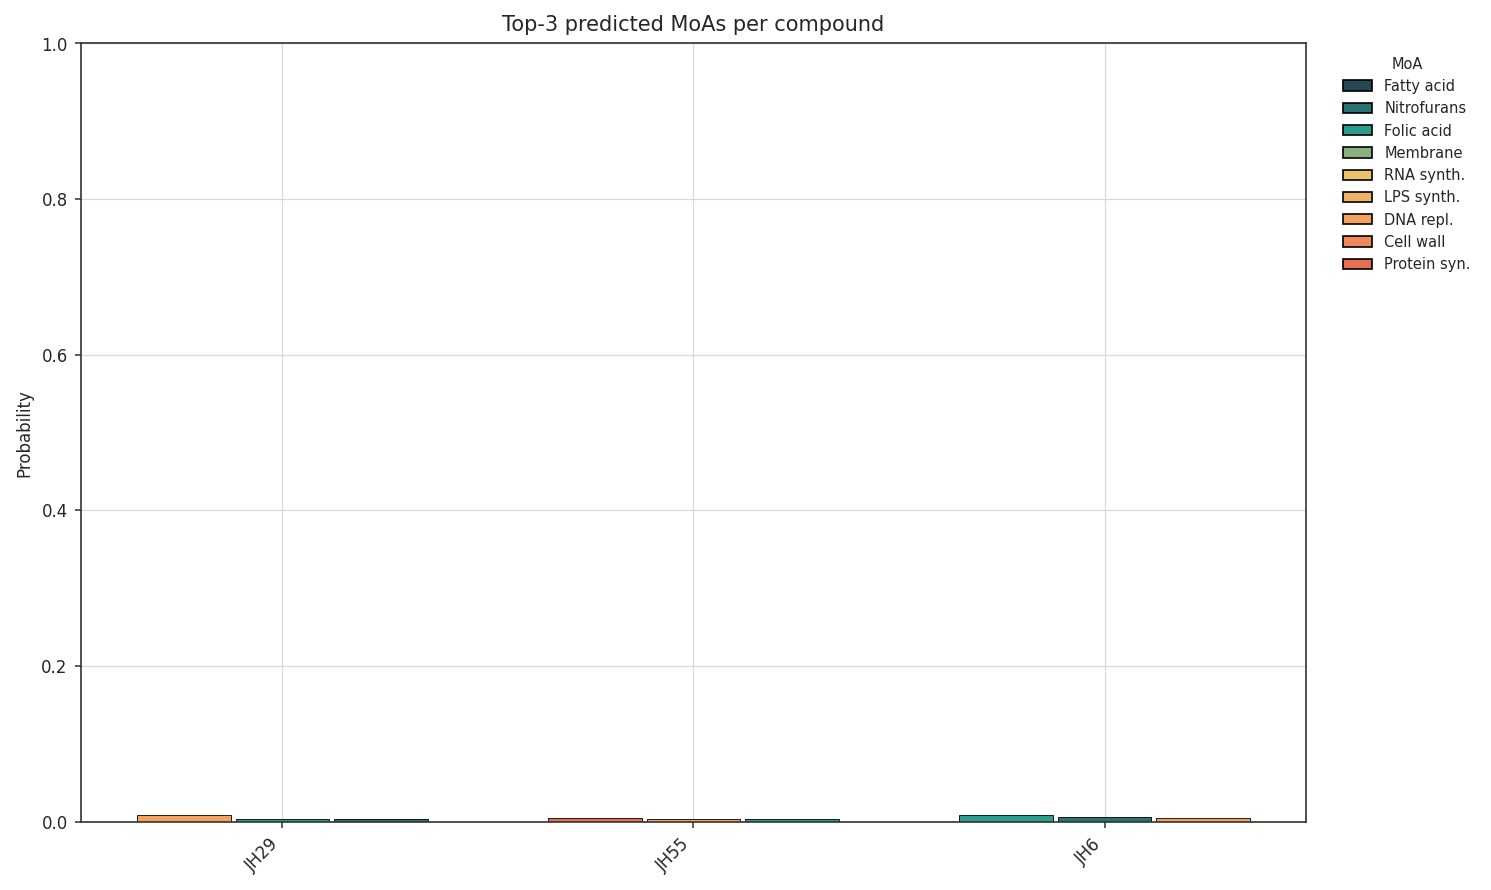

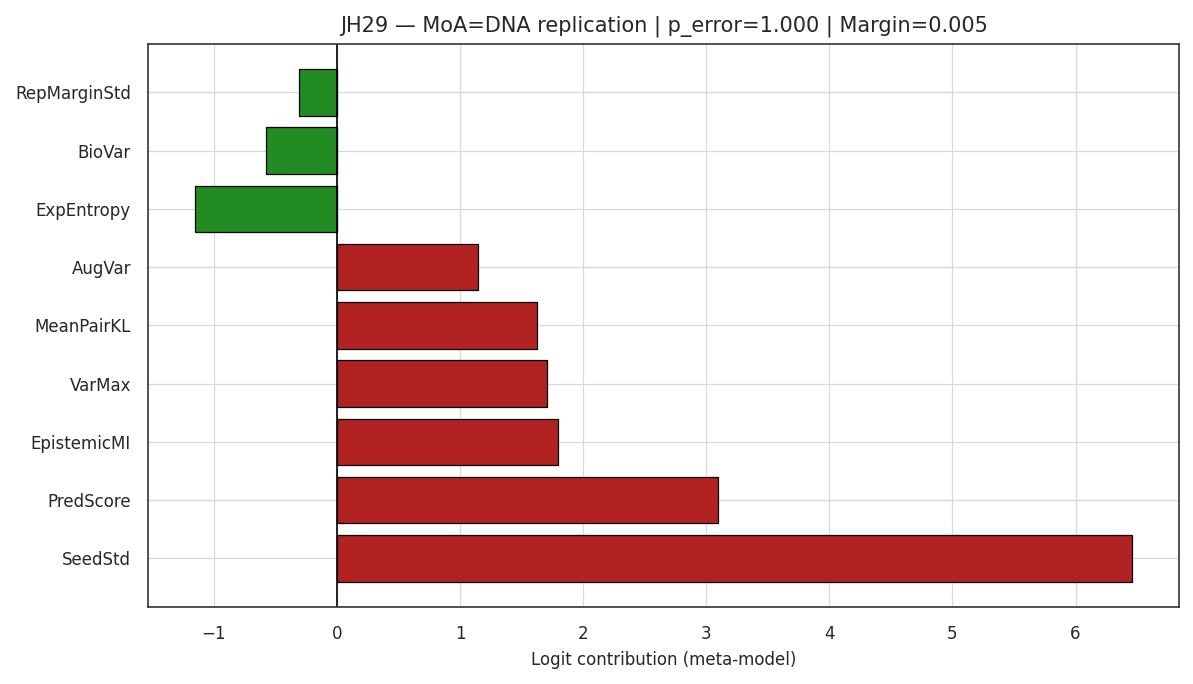

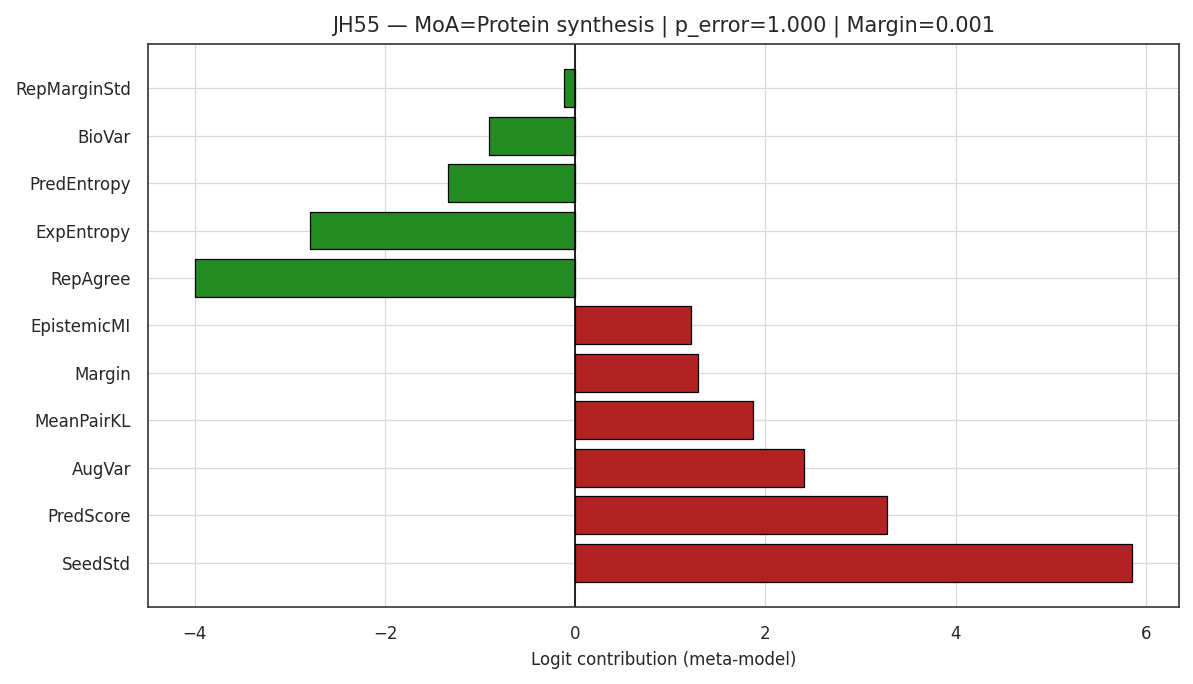

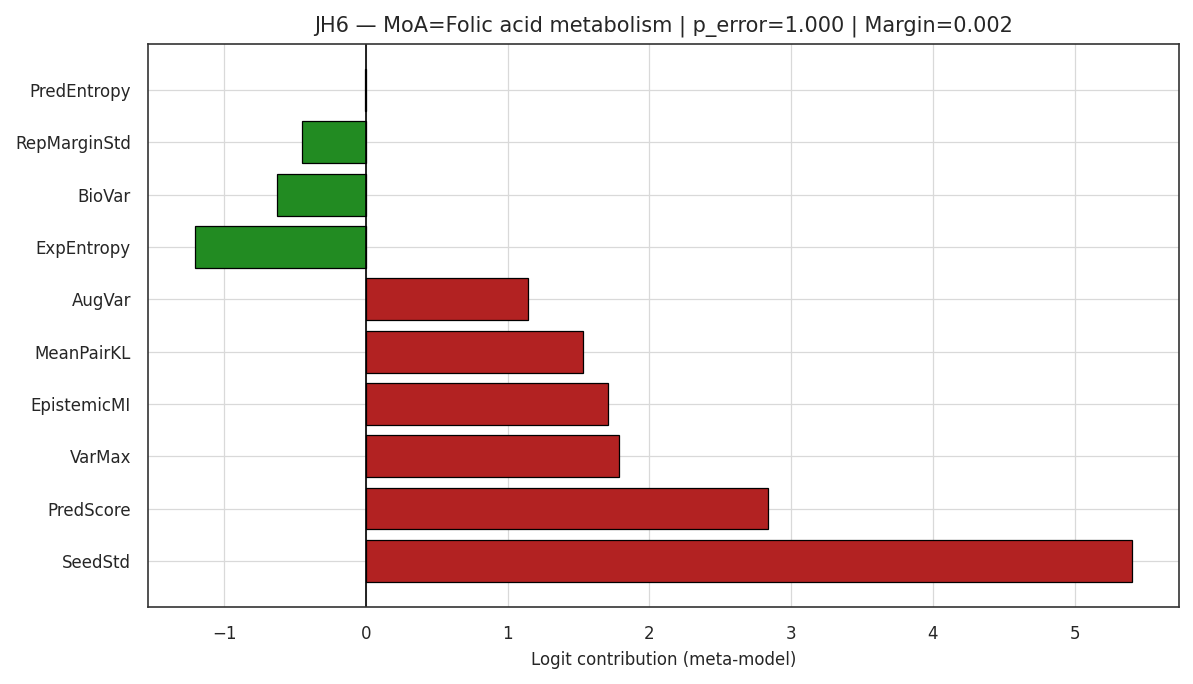

,PredictedMoA,PredScore,SecondMoA,SecondScore,Margin
CompoundID,,,,,
JH29,DNA replication,0.008342,Folic acid metabolism,0.003702,0.004641
JH55,Protein synthesis,0.004053,DNA replication,0.003449,0.000604
JH6,Folic acid metabolism,0.007875,Nitrofurans,0.005386,0.002488


In [4]:

ue_all_modalities = UncertaintyEstimator(
    pred_root="predictions/eclipse_data/non_sig_reduced/",
    meta_dir="models/uncertainty_estimator_adapted/",
    out_dir="predictions/eclipse_data/non_sig_reduced/uncertainty_meta_apply",
    output_prefix="non_sig_reduced",
    abs_min_score_floor=0.05,
    score_floor_factor=0.1,
    margin_floor=0.01,
)
df_all_mods = ue_all_modalities.run()  
ue_all_modalities.plot_p_error_bar()
ue_all_modalities.plot_top3_moas()
ue_all_modalities.plot_waterfall()
ue_all_modalities.comp_summary


# Significant, with original samples removed from training set

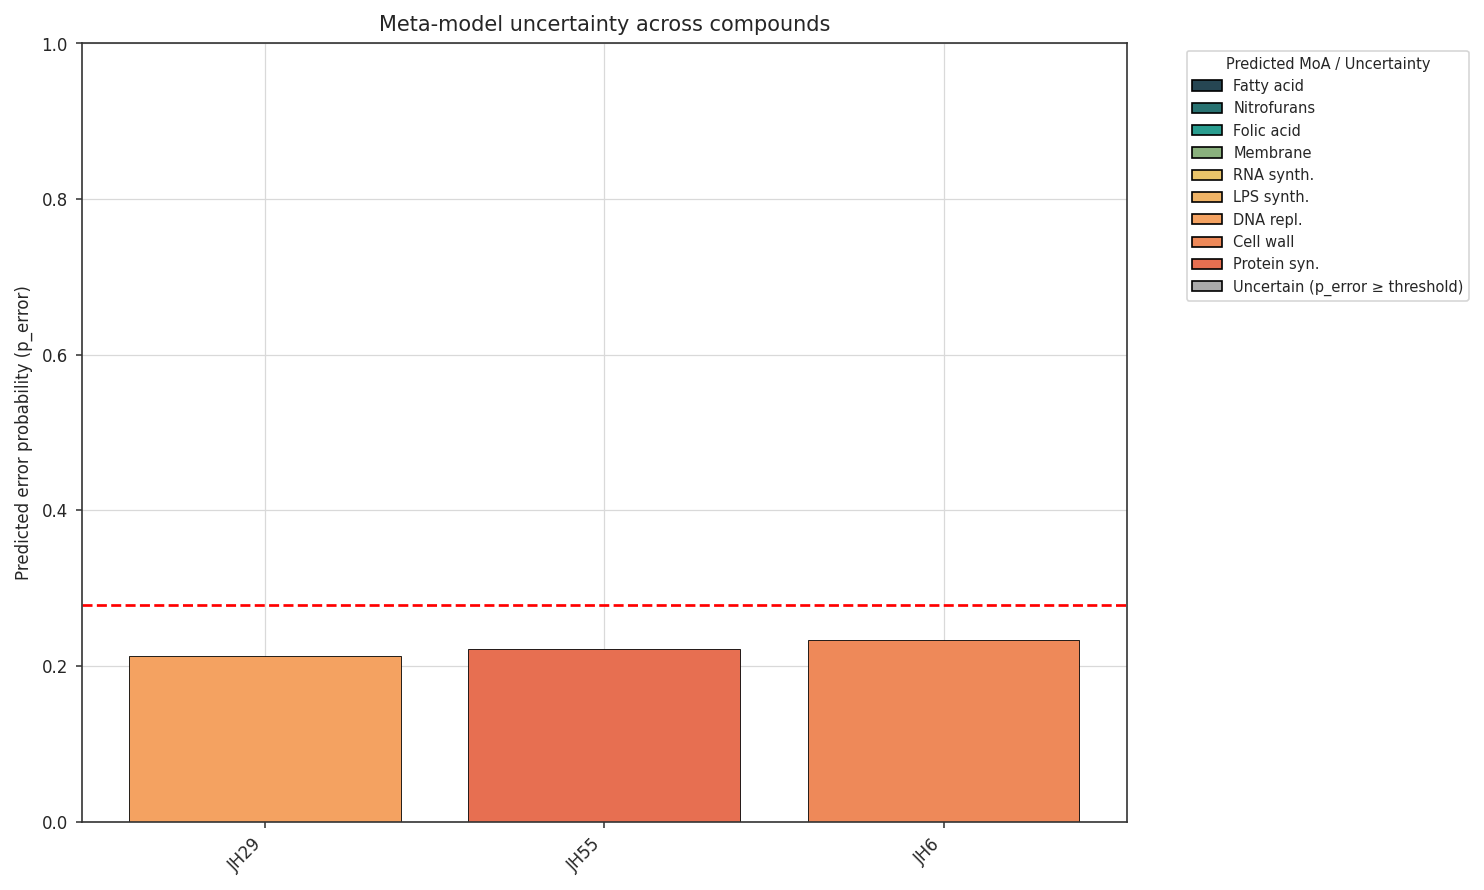

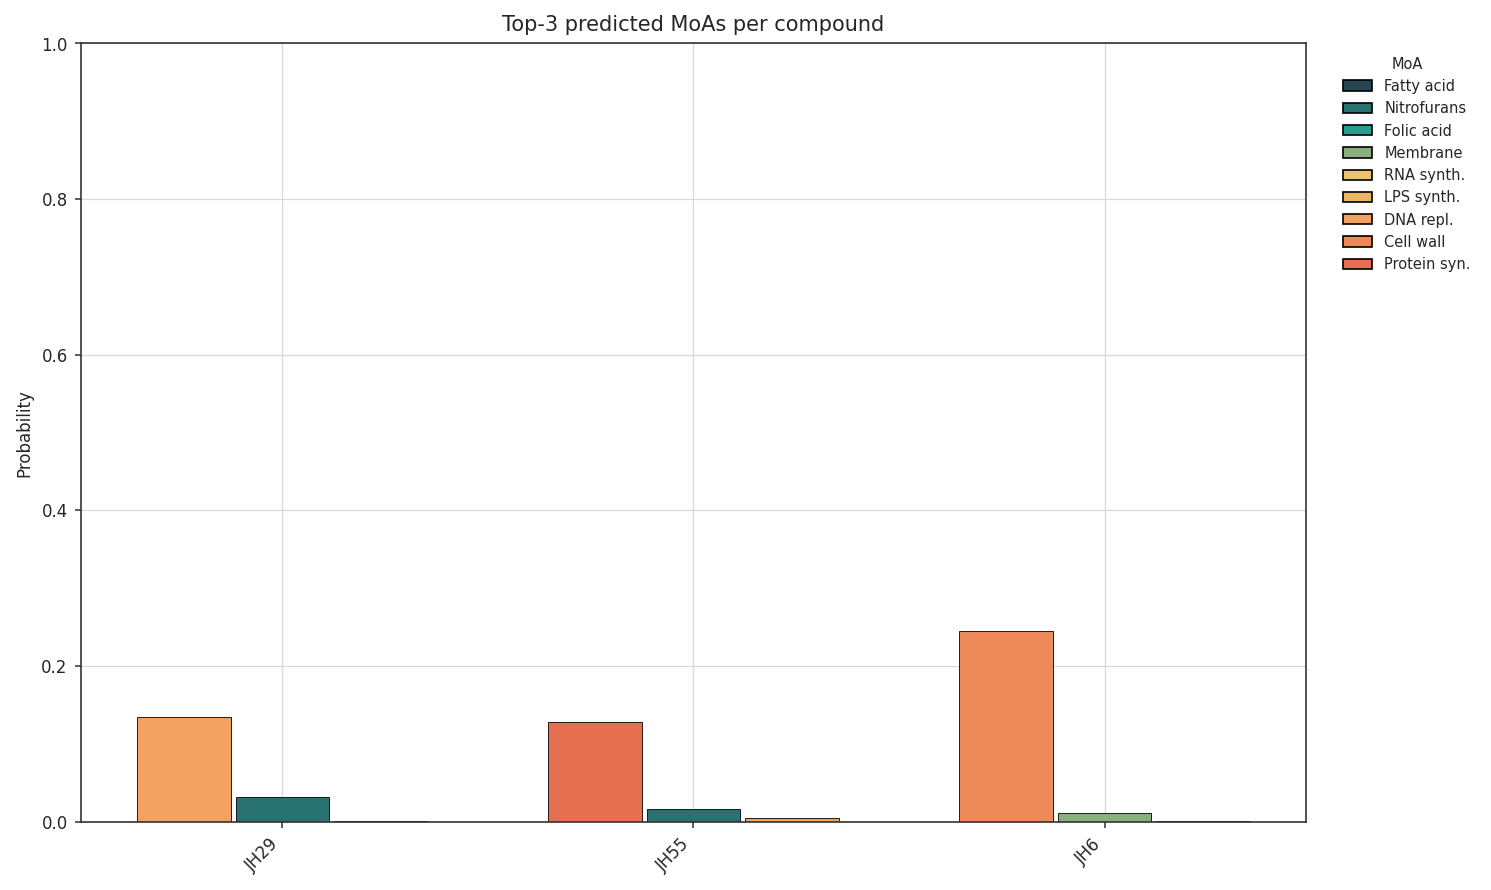

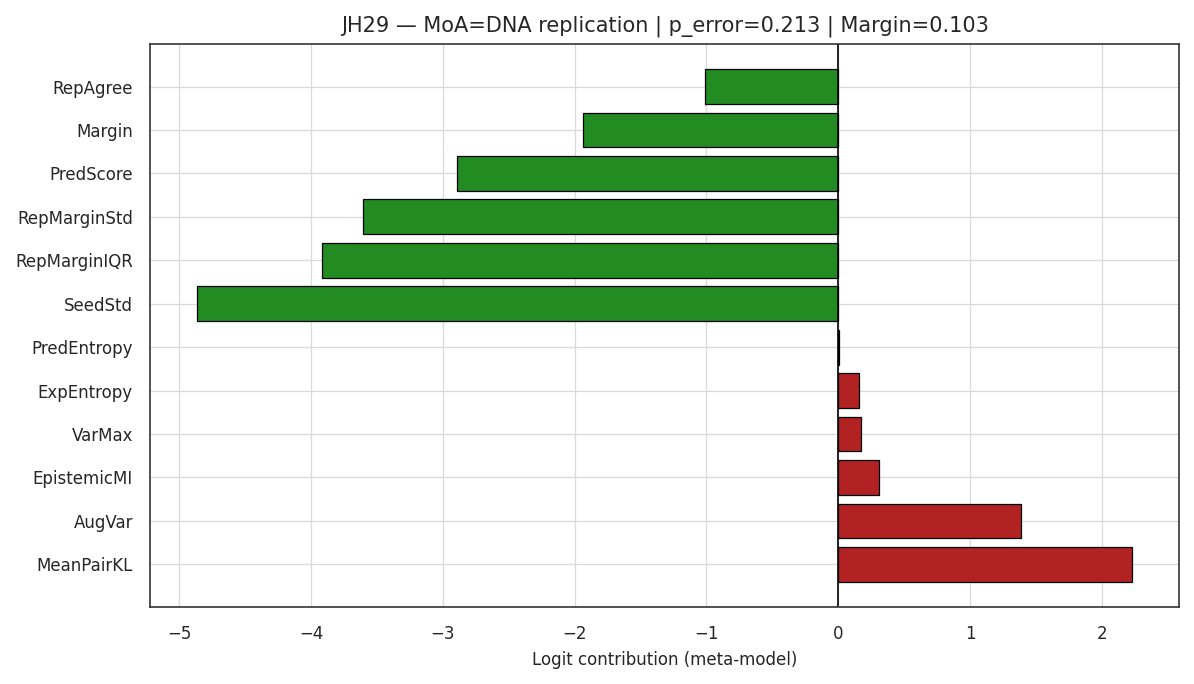

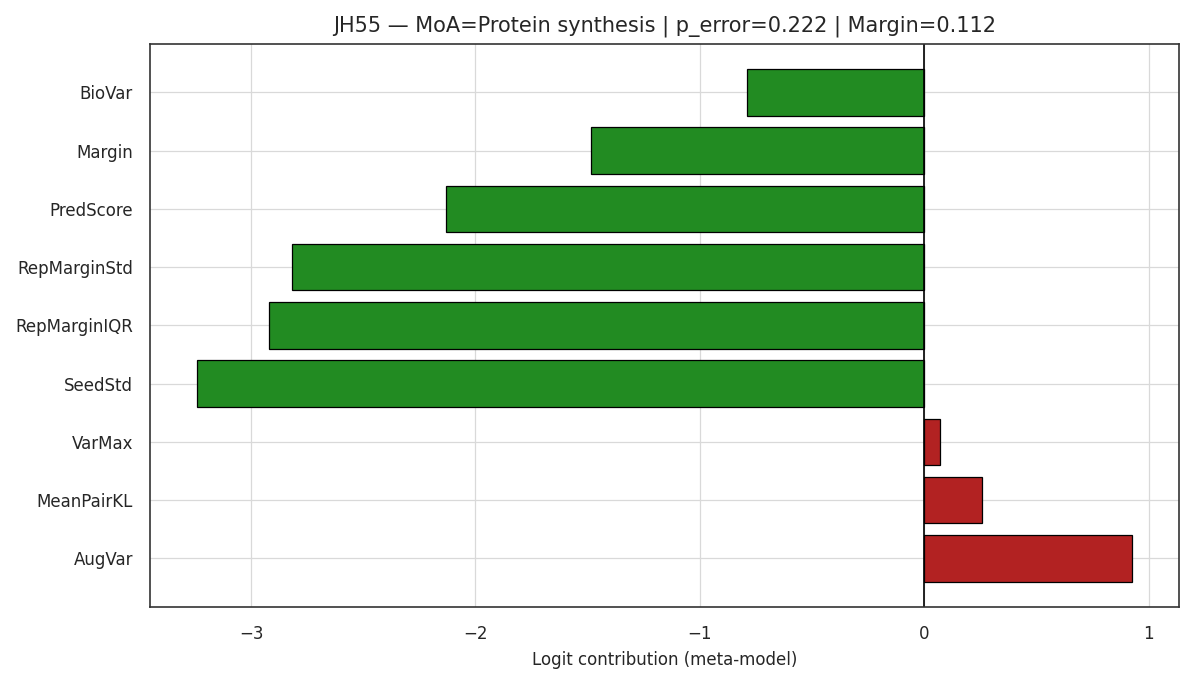

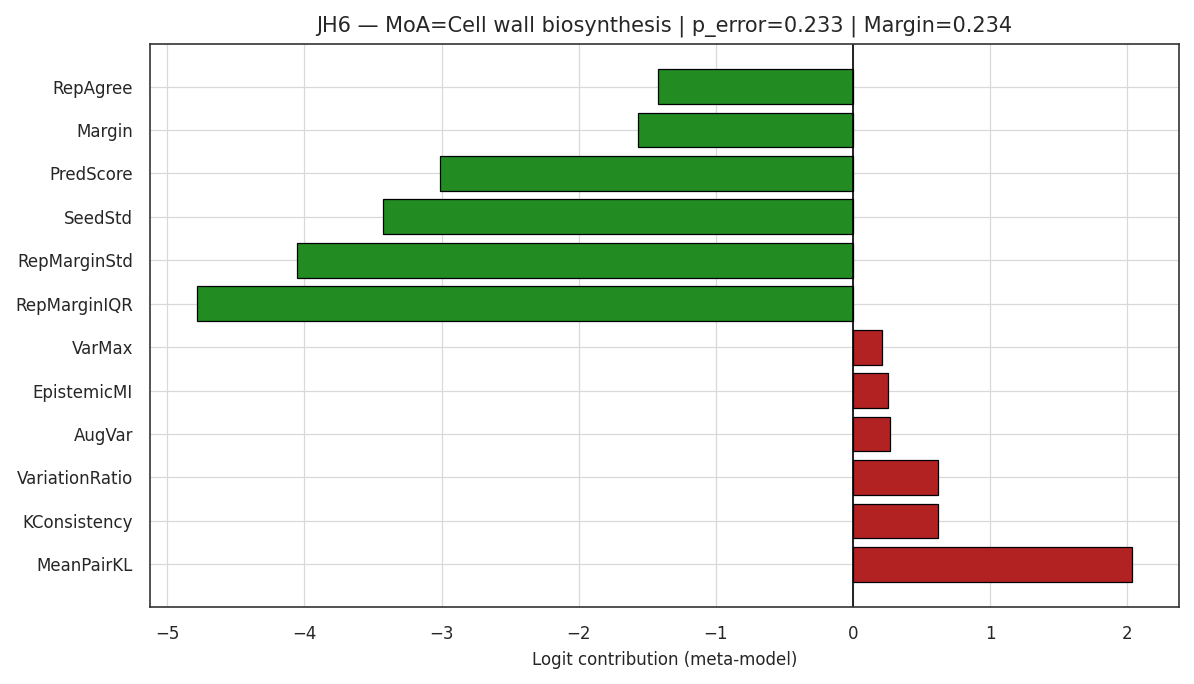

,PredictedMoA,PredScore,SecondMoA,SecondScore,Margin
CompoundID,,,,,
JH29,DNA replication,0.134821,Nitrofurans,0.031355,0.103465
JH55,Protein synthesis,0.128432,Nitrofurans,0.016301,0.112131
JH6,Cell wall biosynthesis,0.244476,Membrane disruption,0.010358,0.234118


In [5]:
ue_all_modalities = UncertaintyEstimator(
    pred_root="predictions/eclipse_data/sig_reduced/",
    meta_dir="models/uncertainty_estimator_adapted/",
    out_dir="predictions/eclipse_data/sig_reduced/uncertainty_meta_apply",
    output_prefix="sig_reduced",
    abs_min_score_floor=0.05,
    score_floor_factor=0.1,
    margin_floor=0.01,
)
df_all_mods = ue_all_modalities.run()  
ue_all_modalities.plot_p_error_bar()
ue_all_modalities.plot_top3_moas()
ue_all_modalities.plot_waterfall()
ue_all_modalities.comp_summary
